In [1]:
import os, shutil

In [ ]:
import os, shutil

train_path = "/content/drive/MyDrive/eyeglass_datasets_backup/train"
test_path = "/content/drive/MyDrive/eyeglass_datasets_backup/test"

combined_path = "/content/drive/MyDrive/eyeglass_dataset_backups_all"

os.makedirs(combined_path, exist_ok=True)

for cls in os.listdir(train_path):
    os.makedirs(os.path.join(combined_path, cls), exist_ok=True)

    # copy from train
    for img in os.listdir(os.path.join(train_path, cls)):
        shutil.copy(os.path.join(train_path, cls, img),
                    os.path.join(combined_path, cls, img))

    # copy from test (if anything left)
    if os.path.exists(os.path.join(test_path, cls)):
        for img in os.listdir(os.path.join(test_path, cls)):
            shutil.copy(os.path.join(test_path, cls, img),
                        os.path.join(combined_path, cls, img))

In [ ]:
for cls in os.listdir(combined_path):
    print(cls, len(os.listdir(os.path.join(combined_path, cls))))

cat-eye 99
oval 100
Rectangle 100
Round 100


In [ ]:
import os
import random

final_train = "/content/drive/MyDrive/final_dataset/train"
final_test = "/content/drive/MyDrive/final_dataset/test"

for cls in os.listdir(combined_path):
    images = os.listdir(os.path.join(combined_path, cls))
    random.shuffle(images)

    split = int(0.8 * len(images))

    train_imgs = images[:split]
    test_imgs = images[split:]

    os.makedirs(os.path.join(final_train, cls), exist_ok=True)
    os.makedirs(os.path.join(final_test, cls), exist_ok=True)

    for img in train_imgs:
        shutil.copy(os.path.join(combined_path, cls, img),
                    os.path.join(final_train, cls, img))

    for img in test_imgs:
        shutil.copy(os.path.join(combined_path, cls, img),
                    os.path.join(final_test, cls, img))

NameError: name 'os' is not defined

In [ ]:
def count_images(folder):
    for cls in os.listdir(folder):
        print(cls, len(os.listdir(os.path.join(folder, cls))))

print("TRAIN:")
count_images(final_train)

print("\nTEST:")
count_images(final_test)

TRAIN:
cat-eye 97
oval 99
Rectangle 98
Round 94

TEST:
cat-eye 58
oval 62
Rectangle 61
Round 57


In [ ]:
import os

base = "/content/drive/MyDrive/final_dataset"

for split in ["train", "test"]:
    print(f"\n{split.upper()}:")
    for cls in os.listdir(os.path.join(base, split)):
        path = os.path.join(base, split, cls)
        print(cls, len(os.listdir(path)))


TRAIN:
cat-eye 97
oval 99
Rectangle 98
Round 94

TEST:
cat-eye 58
oval 62
Rectangle 61
Round 57


In [ ]:
from PIL import Image
import os
import cv2

def remove_corrupt_images(folder):
    for root, dirs, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            try:
                img = Image.open(path)
                img.verify()
            except:
                os.remove(path)

def resize_images(folder, size=(224,224)):
    for root, dirs, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            img = cv2.imread(path)
            if img is None:
                continue
            img = cv2.resize(img, size)
            cv2.imwrite(path, img)

In [ ]:
train_path = "/content/drive/MyDrive/final_dataset/train"

remove_corrupt_images(train_path)
resize_images(train_path)

In [ ]:
test_path = "/content/drive/MyDrive/final_dataset/test"

remove_corrupt_images(test_path)
resize_images(test_path)

In [ ]:
def count_images(folder):
    for cls in os.listdir(folder):
        print(cls, len(os.listdir(os.path.join(folder, cls))))

print("TRAIN:")
count_images(train_path)

print("\nTEST:")
count_images(test_path)

TRAIN:
cat-eye 97
oval 99
Rectangle 98
Round 92

TEST:
cat-eye 58
oval 62
Rectangle 61
Round 57


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator


In [ ]:
train_path = "/content/drive/MyDrive/final_dataset/train"
test_path = "/content/drive/MyDrive/final_dataset/test"

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [ ]:
train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical'
)

Found 386 images belonging to 4 classes.
Found 238 images belonging to 4 classes.


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(4, activation='softmax')  # 4 classes
])

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history = model.fit(
    train_data,
    validation_data=test_data,
    epochs=15
)

Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 54s 3s/step - accuracy: 0.4119 - loss: 1.4238 - val_accuracy: 0.6345 - val_loss: 0.8945
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 486ms/step - accuracy: 0.6166 - loss: 1.0527 - val_accuracy: 0.7521 - val_loss: 0.7488
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 629ms/step - accuracy: 0.6269 - loss: 0.8806 - val_accuracy: 0.7563 - val_loss: 0.7248
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 525ms/step - accuracy: 0.7306 - loss: 0.7711 - val_accuracy: 0.7731 - val_loss: 0.6288
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 629ms/step - accuracy: 0.6917 - loss: 0.7473 - val_accuracy: 0.8193 - val_loss: 0.5651
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 490ms/step - accuracy: 0.7591 - loss: 0.6575 - val_accuracy: 0.7185 - val_loss: 0.6735
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 620ms/step - accuracy: 0.7435 - loss: 0.6741 - val_accuracy: 0.8277 - val_loss: 0.4835
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 481ms/step - accuracy: 0.7979 - loss: 0.5627 - val_accuracy: 0.85

In [ ]:
loss, acc = model.evaluate(test_data)
print("Test Accuracy:", acc)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 110ms/step - accuracy: 0.8529 - loss: 0.4182
Test Accuracy: 0.8529411554336548


In [ ]:
base_model.trainable = True

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(train_data, validation_data=test_data, epochs=5)

Epoch 1/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 103s 4s/step - accuracy: 0.4171 - loss: 1.8585 - val_accuracy: 0.8697 - val_loss: 0.3586
Epoch 2/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 514ms/step - accuracy: 0.4534 - loss: 1.5337 - val_accuracy: 0.8866 - val_loss: 0.3450
Epoch 3/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 666ms/step - accuracy: 0.4741 - loss: 1.4077 - val_accuracy: 0.8908 - val_loss: 0.3574
Epoch 4/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 510ms/step - accuracy: 0.5207 - loss: 1.1608 - val_accuracy: 0.8655 - val_loss: 0.3925
Epoch 5/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 709ms/step - accuracy: 0.5337 - loss: 1.2383 - val_accuracy: 0.8529 - val_loss: 0.4191


In [ ]:
loss, acc = model.evaluate(test_data)
print("Test Accuracy:", acc)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 157ms/step - accuracy: 0.8529 - loss: 0.4191
Test Accuracy: 0.8529411554336548


In [ ]:
base_model.trainable = True

In [ ]:
for layer in base_model.layers[:100]:
    layer.trainable = False

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history_fine = model.fit(
    train_data,
    validation_data=test_data,
    epochs=10
)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 49s 2s/step - accuracy: 0.6295 - loss: 0.9670 - val_accuracy: 0.8697 - val_loss: 0.4272
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 650ms/step - accuracy: 0.6477 - loss: 0.8514 - val_accuracy: 0.8739 - val_loss: 0.4098
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 496ms/step - accuracy: 0.6736 - loss: 0.8100 - val_accuracy: 0.8782 - val_loss: 0.3942
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 654ms/step - accuracy: 0.7176 - loss: 0.7678 - val_accuracy: 0.8782 - val_loss: 0.3776
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 501ms/step - accuracy: 0.7098 - loss: 0.7688 - val_accuracy: 0.8824 - val_loss: 0.3514
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 654ms/step - accuracy: 0.7358 - loss: 0.6399 - val_accuracy: 0.8866 - val_loss: 0.3431
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 7s 510ms/step - accuracy: 0.7202 - loss: 0.7100 - val_accuracy: 0.8908 - val_loss: 0.3313
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 8s 642ms/step - accuracy: 0.7668 - loss: 0.6270 - val_accuracy: 0.89

In [ ]:
loss, acc = model.evaluate(test_data)
print("Final Accuracy:", acc)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 115ms/step - accuracy: 0.8992 - loss: 0.3147
Final Accuracy: 0.8991596698760986


In [ ]:
model.save("/content/drive/MyDrive/eyeglass_model_90.keras")

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

test_datagen = ImageDataGenerator(rescale=1./255)

test_data = test_datagen.flow_from_directory(
    "/content/drive/MyDrive/final_dataset/test",
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 238 images belonging to 4 classes.


In [ ]:
import numpy as np

y_pred_prob = model.predict(test_data)
y_pred = np.argmax(y_pred_prob, axis=1)

y_true = test_data.classes
class_names = list(test_data.class_indices.keys())

8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 718ms/step


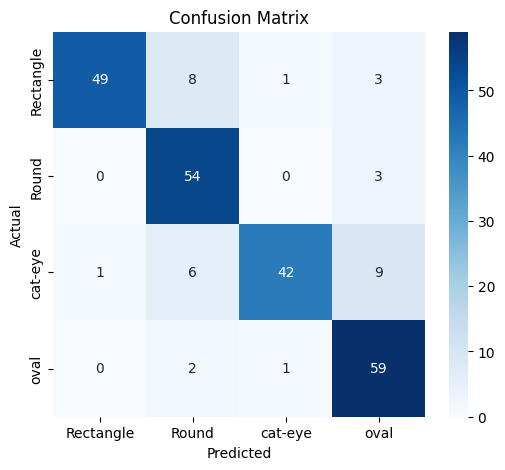

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap="Blues")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

   Rectangle       0.98      0.80      0.88        61
       Round       0.77      0.95      0.85        57
     cat-eye       0.95      0.72      0.82        58
        oval       0.80      0.95      0.87        62

    accuracy                           0.86       238
   macro avg       0.88      0.86      0.86       238
weighted avg       0.88      0.86      0.86       238



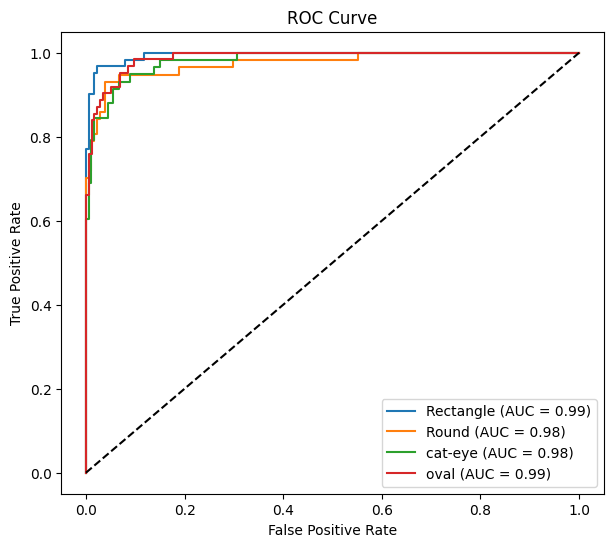

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Convert labels to binary format
y_true_bin = label_binarize(y_true, classes=[0,1,2,3])

plt.figure(figsize=(7,6))

for i in range(len(class_names)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC = {roc_auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(y_true, y_pred, target_names=class_names)

with open("/content/drive/MyDrive/classification_report.txt", "w") as f:
    f.write(report)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.savefig("/content/drive/MyDrive/confusion_matrix.png")
plt.close()

In [ ]:
plt.figure(figsize=(7,6))

for i in range(len(class_names)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC = {roc_auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()

plt.savefig("/content/drive/MyDrive/roc_curve.png")
plt.close()

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "True Label": y_true,
    "Predicted Label": y_pred
})

df.to_csv("/content/drive/MyDrive/predictions.csv", index=False)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

metrics = {
    "accuracy": acc,
    "precision": precision_score(y_true, y_pred, average='weighted'),
    "recall": recall_score(y_true, y_pred, average='weighted'),
    "f1_score": f1_score(y_true, y_pred, average='weighted')
}

import json

with open("/content/drive/MyDrive/metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

**Efficient NetB0**

In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

test_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [ ]:
train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 386 images belonging to 4 classes.
Found 238 images belonging to 4 classes.


In [ ]:
train_data = train_datagen.flow_from_directory(
    train_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=True
)

test_data = test_datagen.flow_from_directory(
    test_path,
    target_size=(224,224),
    batch_size=32,
    class_mode='categorical',
    shuffle=False
)

Found 386 images belonging to 4 classes.
Found 238 images belonging to 4 classes.


In [ ]:
model2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history2 = model2.fit(
    train_data,
    validation_data=test_data,
    epochs=10
)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 48s 2s/step - accuracy: 0.4041 - loss: 1.3742 - val_accuracy: 0.5966 - val_loss: 0.9321
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 202ms/step - accuracy: 0.5933 - loss: 1.0009 - val_accuracy: 0.7689 - val_loss: 0.7012
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 197ms/step - accuracy: 0.7176 - loss: 0.8005 - val_accuracy: 0.8403 - val_loss: 0.5695
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 204ms/step - accuracy: 0.7617 - loss: 0.6337 - val_accuracy: 0.8697 - val_loss: 0.4669
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 204ms/step - accuracy: 0.8031 - loss: 0.5538 - val_accuracy: 0.8613 - val_loss: 0.4164
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 200ms/step - accuracy: 0.8264 - loss: 0.5237 - val_accuracy: 0.8908 - val_loss: 0.3499
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 196ms/step - accuracy: 0.8523 - loss: 0.4761 - val_accuracy: 0.8950 - val_loss: 0.3174
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 197ms/step - accuracy: 0.8523 - loss: 0.4220 - val_accuracy: 0.89

In [ ]:
loss, acc = model2.evaluate(test_data)
print("EfficientNet Accuracy:", acc)

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 302ms/step - accuracy: 0.9412 - loss: 0.2254
EfficientNet Accuracy: 0.9411764740943909


In [ ]:
model2.save("/content/drive/MyDrive/efficientnet_94.keras")

In [ ]:
test_data.reset()

In [ ]:
shuffle=False

In [ ]:
import numpy as np

y_pred_prob = model2.predict(test_data)
y_pred = np.argmax(y_pred_prob, axis=1)

y_true = test_data.classes
class_names = list(test_data.class_indices.keys())

8/8 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step


In [ ]:
from sklearn.metrics import classification_report, accuracy_score

print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=class_names))

Accuracy: 0.9411764705882353
              precision    recall  f1-score   support

   Rectangle       0.98      0.98      0.98        61
       Round       0.85      1.00      0.92        57
     cat-eye       0.96      0.91      0.94        58
        oval       0.98      0.87      0.92        62

    accuracy                           0.94       238
   macro avg       0.94      0.94      0.94       238
weighted avg       0.95      0.94      0.94       238



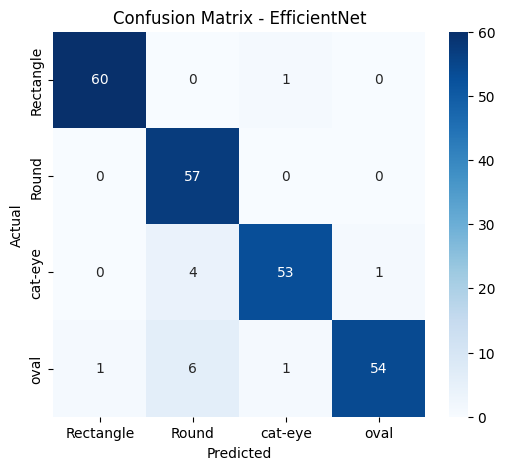

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap="Blues")

plt.title("Confusion Matrix - EfficientNet")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig("/content/drive/MyDrive/efficientnet_confusion_matrix.png", dpi=300)
plt.show()

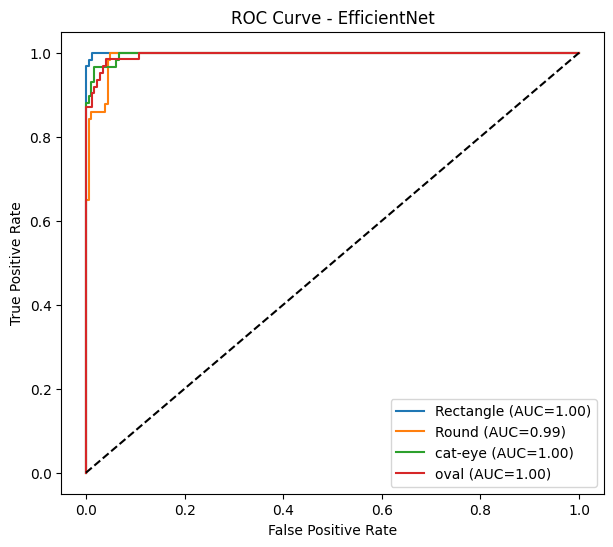

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_true_bin = label_binarize(y_true, classes=[0,1,2,3])

plt.figure(figsize=(7,6))

for i in range(len(class_names)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.2f})")

plt.plot([0,1], [0,1], 'k--')
plt.title("ROC Curve - EfficientNet")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.savefig("/content/drive/MyDrive/efficientnet_roc.png", dpi=300)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(y_true, y_pred, target_names=class_names)

with open("/content/drive/MyDrive/efficientnet_report.txt", "w") as f:
    f.write(report)

**RestNet50**

In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

base_model = ResNet50(
    input_shape=(224,224,3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
model3 = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(4, activation='softmax')
])

In [ ]:
model3.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
history3 = model3.fit(
    train_data,
    validation_data=test_data,
    epochs=10
)

Epoch 1/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.3705 - loss: 1.9838 - val_accuracy: 0.5336 - val_loss: 1.1968
Epoch 2/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 261ms/step - accuracy: 0.5259 - loss: 1.2209 - val_accuracy: 0.6975 - val_loss: 0.8212
Epoch 3/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 253ms/step - accuracy: 0.6373 - loss: 0.8970 - val_accuracy: 0.7731 - val_loss: 0.6934
Epoch 4/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 220ms/step - accuracy: 0.6943 - loss: 0.7795 - val_accuracy: 0.7983 - val_loss: 0.5958
Epoch 5/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 224ms/step - accuracy: 0.7358 - loss: 0.7302 - val_accuracy: 0.8151 - val_loss: 0.5488
Epoch 6/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 229ms/step - accuracy: 0.7720 - loss: 0.6517 - val_accuracy: 0.8782 - val_loss: 0.4446
Epoch 7/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 270ms/step - accuracy: 0.7591 - loss: 0.5444 - val_accuracy: 0.8824 - val_loss: 0.3796
Epoch 8/10
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 215ms/step - accuracy: 0.8187 - loss: 0.4944 - val_accuracy: 0.89

In [ ]:
loss, acc = model3.evaluate(test_data)
print("Model 3 Accuracy:", acc)

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 233ms/step - accuracy: 0.9496 - loss: 0.2852
Model 3 Accuracy: 0.9495798349380493


In [ ]:
model3.save("/content/drive/MyDrive/model3_resnet50.keras")

In [ ]:
test_data.reset()

In [ ]:
shuffle=False

In [ ]:
import numpy as np

y_pred_prob = model3.predict(test_data)
y_pred = np.argmax(y_pred_prob, axis=1)

y_true = test_data.classes
class_names = list(test_data.class_indices.keys())

8/8 ━━━━━━━━━━━━━━━━━━━━ 11s 835ms/step


In [ ]:
from sklearn.metrics import classification_report, accuracy_score

print("Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred, target_names=class_names))

Accuracy: 0.9495798319327731
              precision    recall  f1-score   support

   Rectangle       1.00      0.95      0.97        61
       Round       0.95      0.96      0.96        57
     cat-eye       0.93      0.91      0.92        58
        oval       0.92      0.97      0.94        62

    accuracy                           0.95       238
   macro avg       0.95      0.95      0.95       238
weighted avg       0.95      0.95      0.95       238



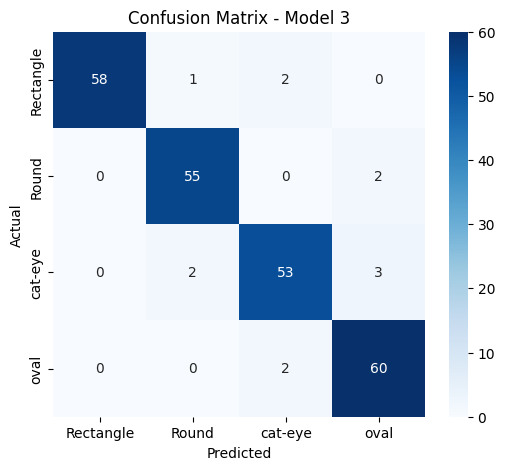

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap="Blues")

plt.title("Confusion Matrix - Model 3")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig("/content/drive/MyDrive/model3_confusion_matrix.png", dpi=300)
plt.show()

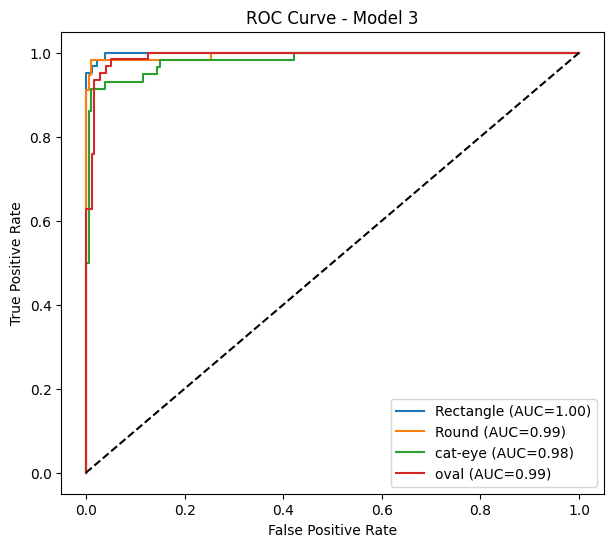

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

y_true_bin = label_binarize(y_true, classes=[0,1,2,3])

plt.figure(figsize=(7,6))

for i in range(len(class_names)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_pred_prob[:, i])
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{class_names[i]} (AUC={roc_auc:.2f})")

plt.plot([0,1],[0,1],'k--')
plt.title("ROC Curve - Model 3")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.savefig("/content/drive/MyDrive/model3_roc.png", dpi=300)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

report = classification_report(y_true, y_pred, target_names=class_names)

with open("/content/drive/MyDrive/model3_report.txt", "w") as f:
    f.write(report)